# Análise Exploratória — Estudantes da rede pública por nível de ensino e Região Administrativa (Rio de Janeiro, 2000 × 2010)

**Disciplina:** Linguagem de Programação (Análise e Visualização de Dados com Python) — 6º período, Bacharelado em Sistemas de Informação, Universidade La Salle
**Fonte:** IPP / Armazém de Dados (Data.Rio), Tabela 892 — IBGE, Censos Demográficos 2000 e 2010 (amostra)

Este notebook é a etapa de **exploração, prototipação e validação**. A lógica reutilizável está em `src/etl.py` (pipeline) e `src/visualizacoes.py` (figuras); aqui ela é executada, inspecionada e validada.

**Perguntas de pesquisa**
- **RQ1** — Como variou a composição da população estudantil da rede pública por etapa de ensino entre 2000 e 2010?
- **RQ2** — Como os estudantes se distribuem entre as RA e onde se concentraram o crescimento e a retração?
- **RQ3** — Existe desigualdade territorial no peso do ensino superior público entre as RA e ela se reduziu no período?

In [1]:
import sys, json
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
from scipy import stats
from src import etl, visualizacoes as viz

pd.set_option("display.width", 200, "display.max_columns", 30, "display.float_format", lambda x: f"{x:,.2f}")
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.1.1 | numpy 2.5.4


## 1. Inspeção do arquivo bruto
O `.xls` tem uma aba por ano, cabeçalho em três linhas mescladas, linhas de título/nota e marcadores textuais do IBGE (`...` e `-`). Por isso ele é lido **sem inferência de tipos** (`dtype=object`).

In [2]:
abas = etl.extrair()
for ano, df in abas.items():
    print(ano, df.shape)
abas[2000].iloc[:10, :8]

INFO | Lendo tabela_892_estudantes_rede_publica_RA_2000_2010.xls


2000 (46, 16)
2010 (46, 15)


,0,1,2,3,4,5,6,7
0,Armazém de Dados,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Tabela 892- Número de estudantes da rede públi...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Regiões Administrativas,NaN,Total,Número de estudantes,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,Creche,Pré-escola,Classe de alfabetização,Alfabetização de adultos,Ensino fundamental ou 1o. Grau
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Regular seriado
7,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
8,Rio de Janeiro (1),NaN,1004604,21799,65921,44782,6091,572090
9,I Portuária,NaN,8315,285,728,585,37,4894


In [3]:
# Notas de rodapé de cada aba (definem o significado dos marcadores)
for ano, df in abas.items():
    print(ano, "→", [str(x) for x in df[0].dropna().tail(3)])

2000 → ['Fonte: Instituto Brasileiro de Geografia e Estatísticas -IBGE, Censo 2000, Amostra, via Banco Multidimensional de Estatísticas.', 'Nota: (1) As diferenças entre a soma das parcelas e seus totais se devem ao fato de serem dados da amostra.', '...    Dado numérico não disponivel.']
2010 → ['XXXIV Cidade de Deus', 'Fonte: Instituto Brasileiro de Geografia e Estatísticas -IBGE, Censo 2010, Amostra.', 'Nota:   -   Dado numérico igual a zero não resultante de arredondamento.']


In [4]:
# Diferenças estruturais entre os anos: os níveis de ensino não são os mesmos
for ano, df in abas.items():
    ini_cab, _, _ = etl.localizar_cabecalho(df)
    print(ano, etl.montar_colunas(df, ini_cab)[3:], "\n")

2000 ['Creche', 'Pré-escola', 'Classe de alfabetização', 'Alfabetização de adultos', 'Ensino fundamental ou 1o. Grau - Regular seriado', 'Ensino fundamental ou 1o. Grau - Regular não seriado', 'Ensino fundamental ou 1o. Grau - Supletivo', 'Ensino médio ou 2o. Grau - Regular seriado', 'Ensino médio ou 2o. Grau - Regular não seriado', 'Ensino médio ou 2o. Grau - Supletivo', 'Pré-vestibular', 'Ensino superior- Graduação', 'Mestrado ou Doutorado'] 

2010 ['Creche', 'Pré-escola', 'Classe de alfabetização', 'Alfabetização de adultos', 'Ensino fundamental ou 1º Grau - Regular', 'Ensino fundamental ou 1º Grau - Supletivo', 'Ensino médio ou 2º Grau - Regular', 'Ensino médio ou 2º Grau - Supletivo', 'Ensino superior - Graduação', 'Especialização de nível Superior', 'Mestrado', 'Doutorado'] 



## 2. Execução do pipeline e validação de qualidade

In [5]:
longo = etl.executar()
longo.head()

INFO | Lendo tabela_892_estudantes_rede_publica_RA_2000_2010.xls


INFO | Ano 2000: 33 linhas territoriais, 13 colunas de nível


INFO | Ano 2010: 34 linhas territoriais, 12 colunas de nível


INFO | Validação 2000: 32 RA | dif. soma RA x município = -0.019% | max dif parcelas x total = 0.000%


INFO | Validação 2010: 33 RA | dif. soma RA x município = 0.000% | max dif parcelas x total = 0.000%


INFO | Salvo: data/processed/estudantes_ra_nivel_longo.{parquet,csv.gz} (837 linhas)


INFO | Salvo: data/processed/estudantes_ra_etapa.{parquet,csv.gz} (335 linhas)


INFO | Salvo: data/processed/variacao_ra_2000_2010.{parquet,csv.gz} (34 linhas)


INFO | Salvo: data/processed/indicador_ensino_superior_ra.{parquet,csv.gz} (67 linhas)


INFO | Pipeline concluído.


,ano,nivel_territorial,ra_codigo,ra_romano,ra_nome,area_planejamento,rotulo_bruto,nivel_original,nivel_harmonizado,etapa,comparavel_2000_2010,estudantes,status_dado,valor_bruto,total_publicado_ra
0,2000,municipio,0,,Município do Rio de Janeiro,Total,Rio de Janeiro (1),Classe de alfabetização,Classe de alfabetização,Educação Infantil,True,"44,782.00",observado,44782,"1,004,604.00"
1,2000,municipio,0,,Município do Rio de Janeiro,Total,Rio de Janeiro (1),Creche,Creche,Educação Infantil,True,"21,799.00",observado,21799,"1,004,604.00"
2,2000,municipio,0,,Município do Rio de Janeiro,Total,Rio de Janeiro (1),Pré-escola,Pré-escola,Educação Infantil,True,"65,921.00",observado,65921,"1,004,604.00"
3,2000,municipio,0,,Município do Rio de Janeiro,Total,Rio de Janeiro (1),Alfabetização de adultos,Alfabetização de adultos,Educação de Jovens e Adultos,True,"6,091.00",observado,6091,"1,004,604.00"
4,2000,municipio,0,,Município do Rio de Janeiro,Total,Rio de Janeiro (1),Fundamental - supletivo,Fundamental supletivo,Educação de Jovens e Adultos,True,"20,737.00",observado,20737,"1,004,604.00"


In [6]:
longo.info()

<class 'pandas.DataFrame'>
RangeIndex: 837 entries, 0 to 836
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype   
---  ------                --------------  -----   
 0   ano                   837 non-null    int16   
 1   nivel_territorial     837 non-null    category
 2   ra_codigo             837 non-null    int16   
 3   ra_romano             837 non-null    str     
 4   ra_nome               837 non-null    str     
 5   area_planejamento     837 non-null    category
 6   rotulo_bruto          837 non-null    str     
 7   nivel_original        837 non-null    category
 8   nivel_harmonizado     837 non-null    category
 9   etapa                 837 non-null    category
 10  comparavel_2000_2010  837 non-null    bool    
 11  estudantes            826 non-null    float64 
 12  status_dado           837 non-null    category
 13  valor_bruto           837 non-null    str     
 14  total_publicado_ra    837 non-null    float64 
dtypes: bool(1), categ

In [7]:
rel = json.loads((etl.PASTA_PROCESSADOS / "relatorio_qualidade.json").read_text(encoding="utf-8"))
for ano, info in rel["anos"].items():
    print(ano, {k: v for k, v in info.items() if k != "celulas_nao_disponiveis"})
print("Células '...' (não disponíveis) em 2000:", len(rel["anos"]["2000"]["celulas_nao_disponiveis"]))
print("RA presentes só em 2010:", rel["ra_somente_2010"])

2000 {'n_regioes_administrativas': 32, 'status_dado': {'observado': 418, 'nao_disponivel': 11, 'zero_absoluto': 0}, 'soma_totais_RA': 1004408.0, 'total_municipio_publicado': 1004604.0, 'dif_RA_vs_municipio_pct': -0.0195, 'max_abs_dif_parcelas_vs_total_pct': 0.0, 'ra_com_maior_dif': 'Município do Rio de Janeiro'}
2010 {'n_regioes_administrativas': 33, 'status_dado': {'observado': 393, 'zero_absoluto': 15, 'nao_disponivel': 0}, 'soma_totais_RA': 1129833.19, 'total_municipio_publicado': 1129833.19, 'dif_RA_vs_municipio_pct': 0.0, 'max_abs_dif_parcelas_vs_total_pct': 0.0, 'ra_com_maior_dif': 'Lagoa'}
Células '...' (não disponíveis) em 2000: 11
RA presentes só em 2010: ['Vigário Geral']


In [8]:
# Rastreabilidade: cada conversão guarda o valor bruto e o status
longo.groupby(["ano", "status_dado"], observed=True).size().unstack(fill_value=0)

status_dado,nao_disponivel,observado,zero_absoluto
ano,,,
2000,11,418,0
2010,0,393,15


In [9]:
# Mapa de harmonização dos níveis de ensino (2000 x 2010)
(longo.drop_duplicates(["ano", "nivel_original"])
      .pivot_table(index=["etapa", "nivel_harmonizado"], columns="ano", values="nivel_original",
                   aggfunc="first", observed=True))

ano                                                                                 2000                      2010
etapa                        nivel_harmonizado                                                                    
Educação Infantil            Classe de alfabetização             Classe de alfabetização   Classe de alfabetização
                             Creche                                               Creche                    Creche
                             Pré-escola                                       Pré-escola                Pré-escola
Educação de Jovens e Adultos Alfabetização de adultos           Alfabetização de adultos  Alfabetização de adultos
                             Fundamental supletivo               Fundamental - supletivo   Fundamental - supletivo
                             Médio supletivo                           Médio - supletivo         Médio - supletivo
Ensino Fundamental           Fundamental regular       Fundamental - regular não seriado     Fundamental - regular
Ensino Médio                 Médio regular                   Médio - regular não seriado           Médio - regular
Ensino Superior              Especialização                                          NaN            Especialização
                             Mestrado/doutorado                    Mestrado ou doutorado                 Doutorado
                             Superior graduação                     Superior - graduação      Superior - graduação
Pré-vestibular               Pré-vestibular                               Pré-vestibular                       NaN

In [10]:
# Testes de sanidade (falham explicitamente se algo estiver errado)
assert longo["estudantes"].dropna().ge(0).all(), "valores negativos"
assert not longo.duplicated(["ano", "ra_codigo", "nivel_original"]).any(), "duplicidades"
assert abs(rel["anos"]["2000"]["dif_RA_vs_municipio_pct"]) < 0.1
assert abs(rel["anos"]["2010"]["dif_RA_vs_municipio_pct"]) < 0.1
print("OK — todas as verificações passaram")

OK — todas as verificações passaram


## 3. Estatística descritiva

In [11]:
variacao = pd.read_parquet(etl.PASTA_PROCESSADOS / "variacao_ra_2000_2010.parquet")
originais = variacao[~variacao["unidade_compatibilizada"]]
originais[["estudantes_2000", "estudantes_2010", "variacao_pct", "taxa_anual_pct"]].describe()

,estudantes_2000,estudantes_2010,variacao_pct,taxa_anual_pct
count,32.00,33.00,32.00,32.00
mean,"31,320.53","34,023.01",16.69,1.35
std,"26,609.74","26,752.84",25.18,2.21
min,542.00,764.76,-39.95,-4.97
25%,"13,001.75","15,623.29",-3.37,-0.34
50%,"22,475.50","27,915.03",16.48,1.54
75%,"43,042.00","35,672.28",25.54,2.30
max,"103,771.00","105,448.33",71.50,5.54


In [12]:
# Assimetria e curtose da distribuição de estudantes por RA
for ano in (2000, 2010):
    x = originais[f"estudantes_{ano}"].dropna()
    print(ano, f"assimetria={stats.skew(x):.2f}  curtose={stats.kurtosis(x):.2f}  CV={x.std()/x.mean():.2f}")

2000 assimetria=1.24  curtose=0.55  CV=0.85
2010 assimetria=1.34  curtose=0.95  CV=0.79


## 4. RQ1 — Composição por etapa de ensino

In [13]:
etapa = pd.read_parquet(etl.PASTA_PROCESSADOS / "estudantes_ra_etapa.parquet")
mun = etapa[etapa["ra_codigo"] == 0].pivot(index="etapa", columns="ano", values=["estudantes", "participacao_pct"])
mun[("var_%", "")] = 100 * (mun[("estudantes", 2010)] / mun[("estudantes", 2000)] - 1)
mun[("var_pp", "")] = mun[("participacao_pct", 2010)] - mun[("participacao_pct", 2000)]
mun

estudantes            participacao_pct        var_% var_pp
ano                                2000       2010             2000  2010              
etapa                                                                                  
Educação Infantil            132,502.00 177,822.07            13.22 15.84  34.20   2.62
Educação de Jovens e Adultos  32,268.00 106,631.84             3.22  9.50 230.46   6.28
Ensino Fundamental           592,663.00 536,907.57            59.12 47.82  -9.41 -11.30
Ensino Médio                 181,027.00 209,859.23            18.06 18.69  15.93   0.63
Ensino Superior               63,979.00  91,538.50             6.38  8.15  43.08   1.77

In [14]:
# Detalhe por nível harmonizado (inclui níveis exclusivos de um dos anos)
det = (longo[longo["ra_codigo"] == 0]
       .pivot_table(index=["etapa", "nivel_harmonizado"], columns="ano", values="estudantes",
                    aggfunc="sum", observed=True))
det["var_%"] = 100 * (det[2010] / det[2000] - 1)
det

ano                                                         2000       2010  var_%
etapa                        nivel_harmonizado                                    
Educação Infantil            Classe de alfabetização   44,782.00  67,839.38  51.49
                             Creche                    21,799.00  47,705.89 118.84
                             Pré-escola                65,921.00  62,276.80  -5.53
Educação de Jovens e Adultos Alfabetização de adultos   6,091.00  16,912.39 177.66
                             Fundamental supletivo     20,737.00  40,496.92  95.29
                             Médio supletivo            5,440.00  49,222.53 804.83
Ensino Fundamental           Fundamental regular      592,663.00 536,907.57  -9.41
Ensino Médio                 Médio regular            181,027.00 209,859.23  15.93
Ensino Superior              Especialização                  NaN   7,073.99    NaN
                             Mestrado/doutorado         8,981.00  12,103.75  34.77
                             Superior graduação        54,998.00  79,434.75  44.43
Pré-vestibular               Pré-vestibular             2,165.00        NaN    NaN

In [15]:
tot = etapa[etapa["ra_codigo"] == 0].groupby("ano")["estudantes"].sum()
print("Total comparável:", tot.round(0).to_dict(), f"→ variação {100*(tot[2010]/tot[2000]-1):.1f}%")

Total comparável: {2000: 1002439.0, 2010: 1122759.0} → variação 12.0%


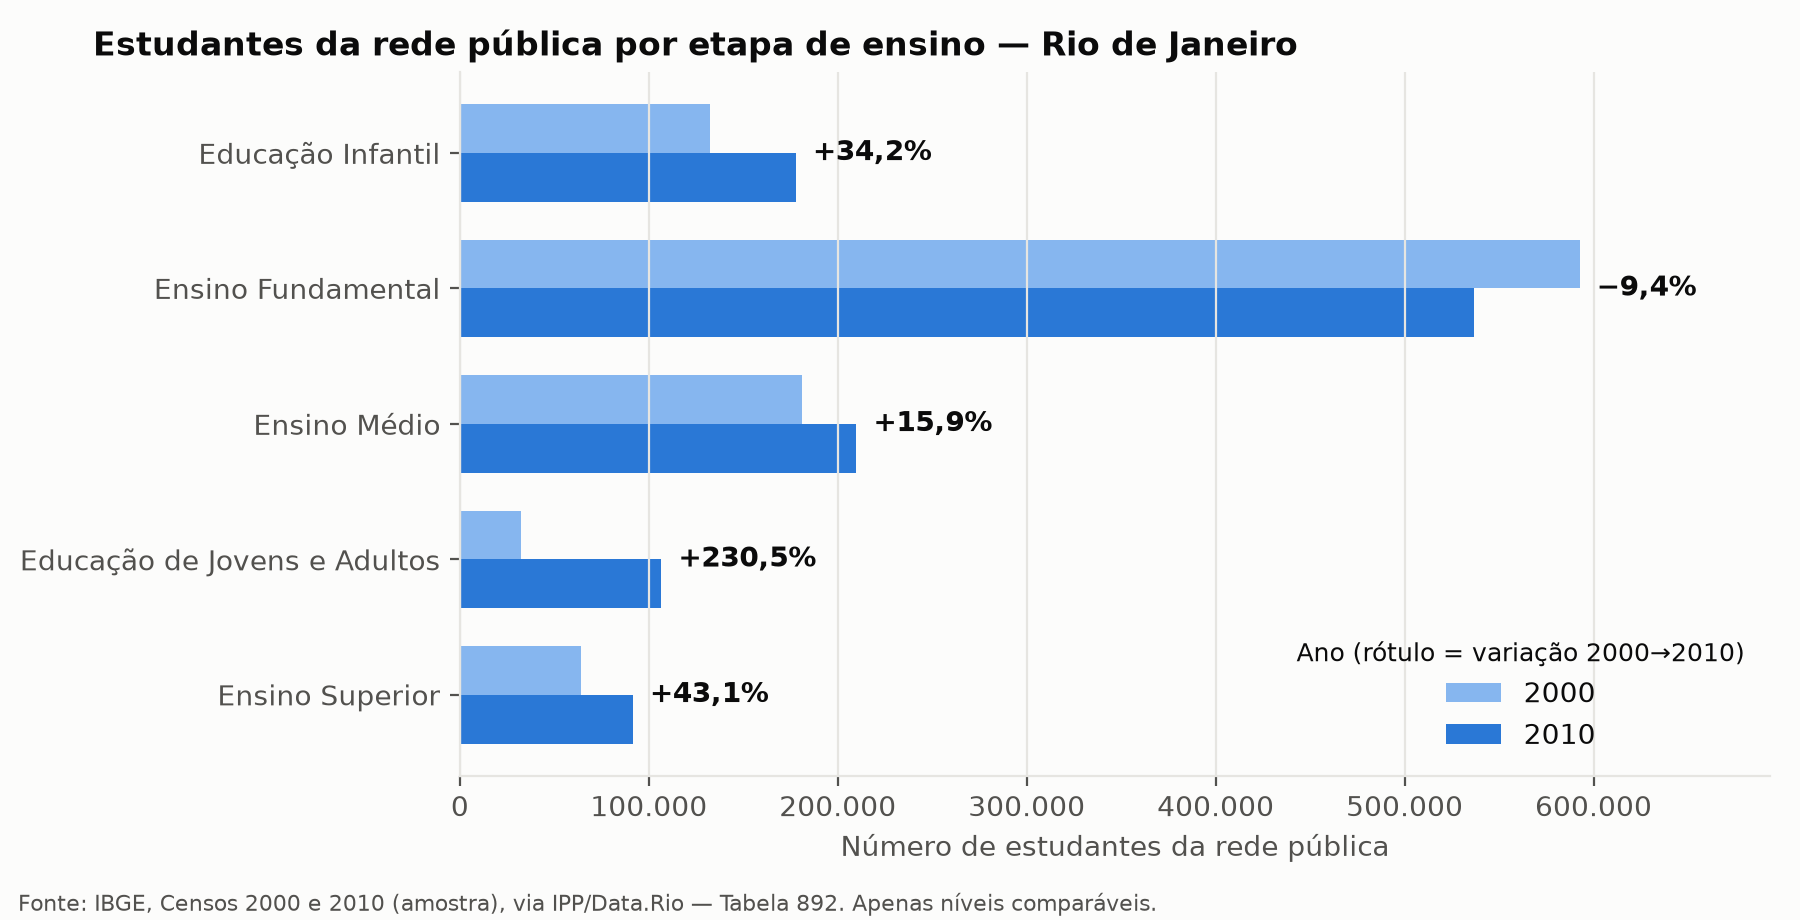

In [16]:
from IPython.display import Image, IFrame
viz.fig1_etapas_municipio(etapa)
Image(filename=str(viz.PASTA_FIGURAS / "fig1_etapas_municipio.png"), width=800)

In [17]:
viz.fig2_composicao_ap(etapa)
IFrame("../docs/assets/interativos/fig2_composicao_ap.html", width="100%", height=580)

## 5. RQ2 — Distribuição territorial, concentração e variação

In [18]:
ap = (etapa[etapa["ra_codigo"] > 0].groupby(["area_planejamento", "ano"], observed=True)["estudantes"].sum().unstack())
ap["var_%"] = 100 * (ap[2010] / ap[2000] - 1)
for a in (2000, 2010):
    ap[f"part_{a}_%"] = 100 * ap[a] / ap[a].sum()
ap

ano,2000,2010,var_%,part_2000_%,part_2010_%
area_planejamento,,,,,
AP1,"47,385.00","63,367.07",33.73,4.73,5.64
AP2,"106,602.00","121,152.71",13.65,10.64,10.79
AP3,"401,640.00","446,259.48",11.11,40.07,39.75
AP4,"106,720.00","136,687.35",28.08,10.65,12.17
AP5,"339,910.00","355,292.59",4.53,33.91,31.64


In [19]:
def concentracao(x):
    x = np.asarray(x.dropna(), dtype=float)
    s = np.sort(x)[::-1]
    return {"n_RA": len(x), "Gini": etl.gini(x), "top5_%": 100 * s[:5].sum() / s.sum(),
            "HHI": ((100 * x / x.sum()) ** 2).sum()}
pd.DataFrame({a: concentracao(originais[f"estudantes_{a}"]) for a in (2000, 2010)})

,2000,2010
n_RA,32.00,33.00
Gini,0.44,0.40
top5_%,41.23,39.21
HHI,531.02,484.71


In [20]:
# Compatibilização territorial: Penha (2000) x Penha + Vigário Geral (2010)
variacao[variacao["ra_nome"].isin(["Penha", "Vigário Geral", "Penha + Vigário Geral"])]

,ra_codigo,ra_nome,area_planejamento,estudantes_2000,estudantes_2010,unidade_compatibilizada,variacao_abs,variacao_pct,taxa_anual_pct,participacao_municipio_2000_pct,participacao_municipio_2010_pct
10,11,Penha,AP3,"55,547.00","33,353.81",False,"-22,193.19",-39.95,-4.97,5.54,2.97
30,31,Vigário Geral,AP3,NaN,"31,920.10",False,NaN,NaN,NaN,NaN,2.84
33,1131,Penha + Vigário Geral,AP3,"55,547.00","65,273.91",True,"9,726.91",17.51,1.63,5.54,5.81


In [21]:
# Outliers da variação percentual (regra de Tukey, 1,5 x IQR) — usando a unidade compatibilizada
comp = variacao[~variacao["ra_nome"].isin(["Penha", "Vigário Geral"])].dropna(subset=["variacao_pct"])
q1, q3 = comp["variacao_pct"].quantile([.25, .75]); iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
print(f"Q1={q1:.1f}%  Q3={q3:.1f}%  limites=[{lim_inf:.1f}%, {lim_sup:.1f}%]")
comp.loc[(comp["variacao_pct"] < lim_inf) | (comp["variacao_pct"] > lim_sup), ["ra_nome", "area_planejamento", "variacao_pct"]]

Q1=-2.6%  Q3=25.5%  limites=[-44.9%, 67.8%]


,ra_nome,area_planejamento,variacao_pct
0,Portuária,AP1,68.16
23,Barra da Tijuca,AP4,71.50


In [22]:
comp.nlargest(5, "variacao_abs")[["ra_nome", "area_planejamento", "variacao_abs", "variacao_pct"]]

,ra_nome,area_planejamento,variacao_abs,variacao_pct
15,Jacarepaguá,AP4,"16,471.61",20.98
18,Santa Cruz,AP5,"14,201.65",18.44
23,Barra da Tijuca,AP4,"13,041.59",71.50
29,Maré,AP3,"11,514.30",48.20
33,Penha + Vigário Geral,AP3,"9,726.91",17.51


In [23]:
comp.nsmallest(5, "variacao_pct")[["ra_nome", "area_planejamento", "variacao_abs", "variacao_pct"]]

,ra_nome,area_planejamento,variacao_abs,variacao_pct
3,Botafogo,AP2,"-2,333.08",-10.27
19,Ilha do Governador,AP3,"-2,827.85",-8.54
31,Realengo,AP5,"-3,296.87",-6.93
1,Centro,AP1,-247.91,-4.91
5,Lagoa,AP2,-627.21,-4.58


In [24]:
viz.fig3_variacao_ra(variacao); viz.fig4_lorenz(variacao)
IFrame("../docs/assets/interativos/fig3_variacao_ra.html", width="100%", height=840)

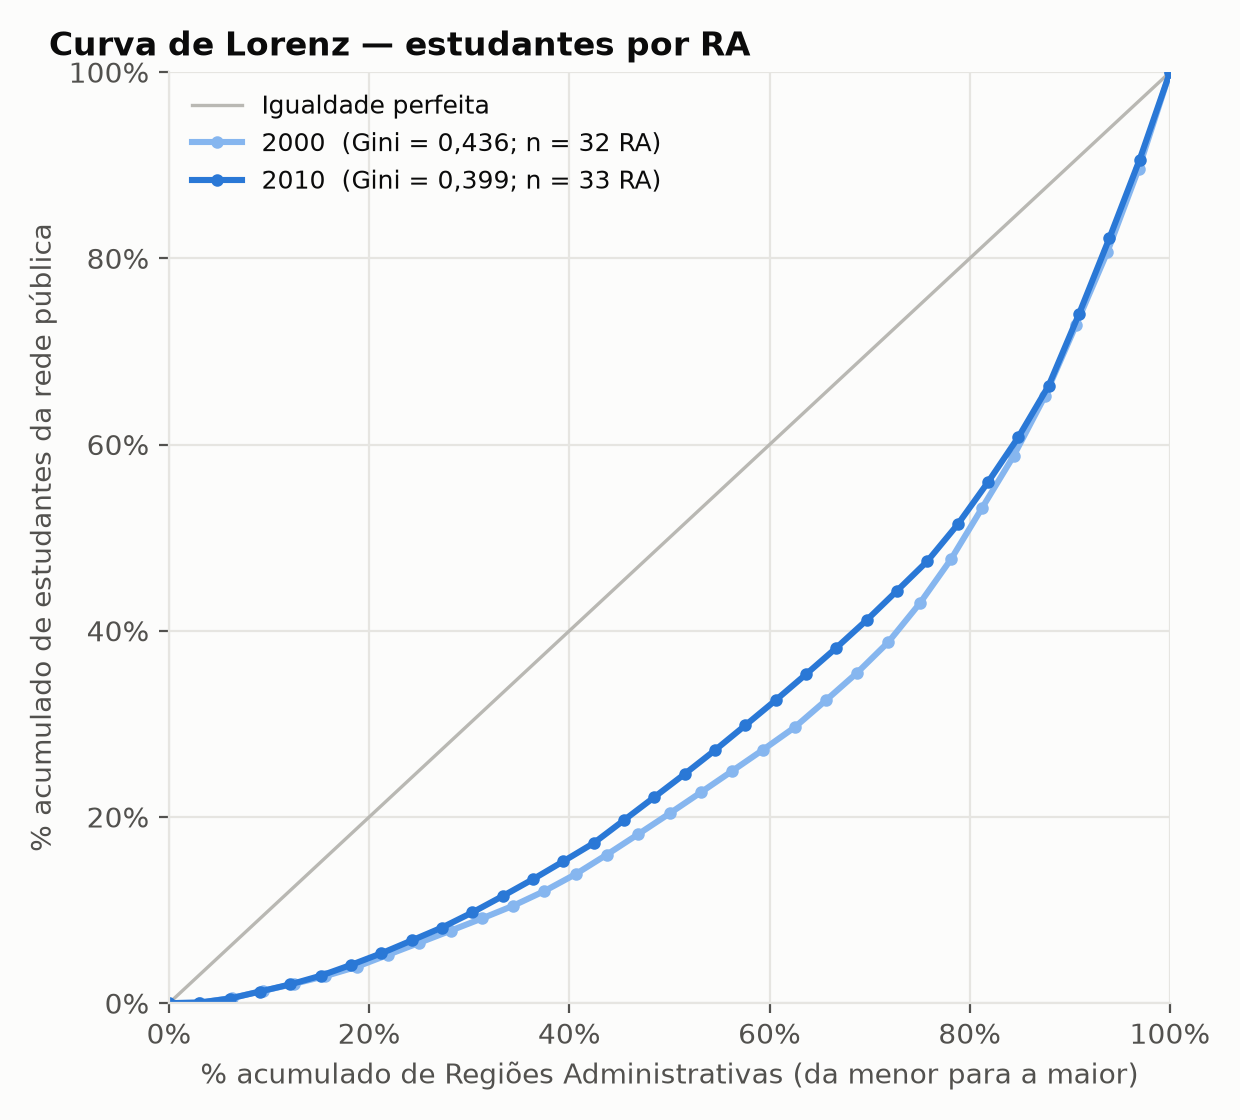

In [25]:
Image(filename=str(viz.PASTA_FIGURAS / "fig4_lorenz_concentracao.png"), width=520)

## 6. RQ3 — Peso do ensino superior público por RA

In [26]:
sup = pd.read_parquet(etl.PASTA_PROCESSADOS / "indicador_ensino_superior_ra.parquet")
p = sup[sup["ra_codigo"] > 0].pivot(index="ra_nome", columns="ano", values="pct_superior")
resumo = {}
for a in (2000, 2010):
    y = p[a].dropna(); q1, q3 = y.quantile([.25, .75]); iqr = q3 - q1
    resumo[a] = {"média": y.mean(), "mediana": y.median(), "desvio": y.std(), "CV": y.std() / y.mean(),
                 "mín": y.min(), "máx": y.max(), "razão máx/mín": y.max() / y.min(),
                 "amplitude (p.p.)": y.max() - y.min(),
                 "outliers (Tukey)": ", ".join(y[(y > q3 + 1.5 * iqr) | (y < q1 - 1.5 * iqr)].index)}
pd.DataFrame(resumo)

,2000,2010
média,8.05,10.02
mediana,4.18,6.10
desvio,8.84,10.27
CV,1.10,1.02
mín,0.64,1.21
máx,33.97,45.01
razão máx/mín,53.26,37.34
amplitude (p.p.),33.33,43.80
outliers (Tukey),"Botafogo, Copacabana, Tijuca, Vila Isabel",Botafogo


In [27]:
pp = p.dropna()
rho = stats.spearmanr(pp[2000], pp[2010]); r = stats.pearsonr(pp[2000], pp[2010])
print(f"Spearman ρ = {rho.statistic:.3f} (p = {rho.pvalue:.1e}) | Pearson r = {r.statistic:.3f}")
delta = (pp[2010] - pp[2000]).sort_values()
print(f"RA com aumento do peso do superior: {(delta > 0).sum()} de {len(delta)} | mediana Δ = {delta.median():.2f} p.p.")
delta.to_frame("Δ p.p.").T

Spearman ρ = 0.940 (p = 1.4e-15) | Pearson r = 0.964
RA com aumento do peso do superior: 28 de 32 | mediana Δ = 1.66 p.p.


ra_nome,Vila Isabel,Paquetá,Rio Comprido,Tijuca,Portuária,Ramos,Complexo do Alemão,Santa Cruz,Guaratiba,Rocinha,Pavuna,Inhaúma,São Cristóvão,Bangu,Cidade de Deus,...,Jacarezinho,Realengo,Barra da Tijuca,Jacarepaguá,Campo Grande,Madureira,Ilha do Governador,Irajá,Lagoa,Penha,Méier,Santa Teresa,Copacabana,Centro,Botafogo
Δ p.p.,-4.03,-2.26,-1.40,-0.33,0.13,0.23,0.57,0.63,0.81,0.92,1.16,1.27,1.42,1.46,1.56,...,1.81,1.90,2.06,2.08,2.15,2.31,2.85,3.11,4.20,4.59,5.54,5.78,6.54,8.82,11.03


In [28]:
# Correlação entre o peso do superior em 2010 e o crescimento total da RA
m = comp.merge(sup.query("ano == 2010")[["ra_nome", "pct_superior"]], on="ra_nome", how="inner")
print(stats.spearmanr(m["pct_superior"], m["variacao_pct"]))

SignificanceResult(statistic=np.float64(-0.42177419354838713), pvalue=np.float64(0.01811300725016952))


In [29]:
viz.fig5_halteres_superior(sup); viz.fig6_dispersao_superior(sup)
IFrame("../docs/assets/interativos/fig5_superior_ra.html", width="100%", height=880)

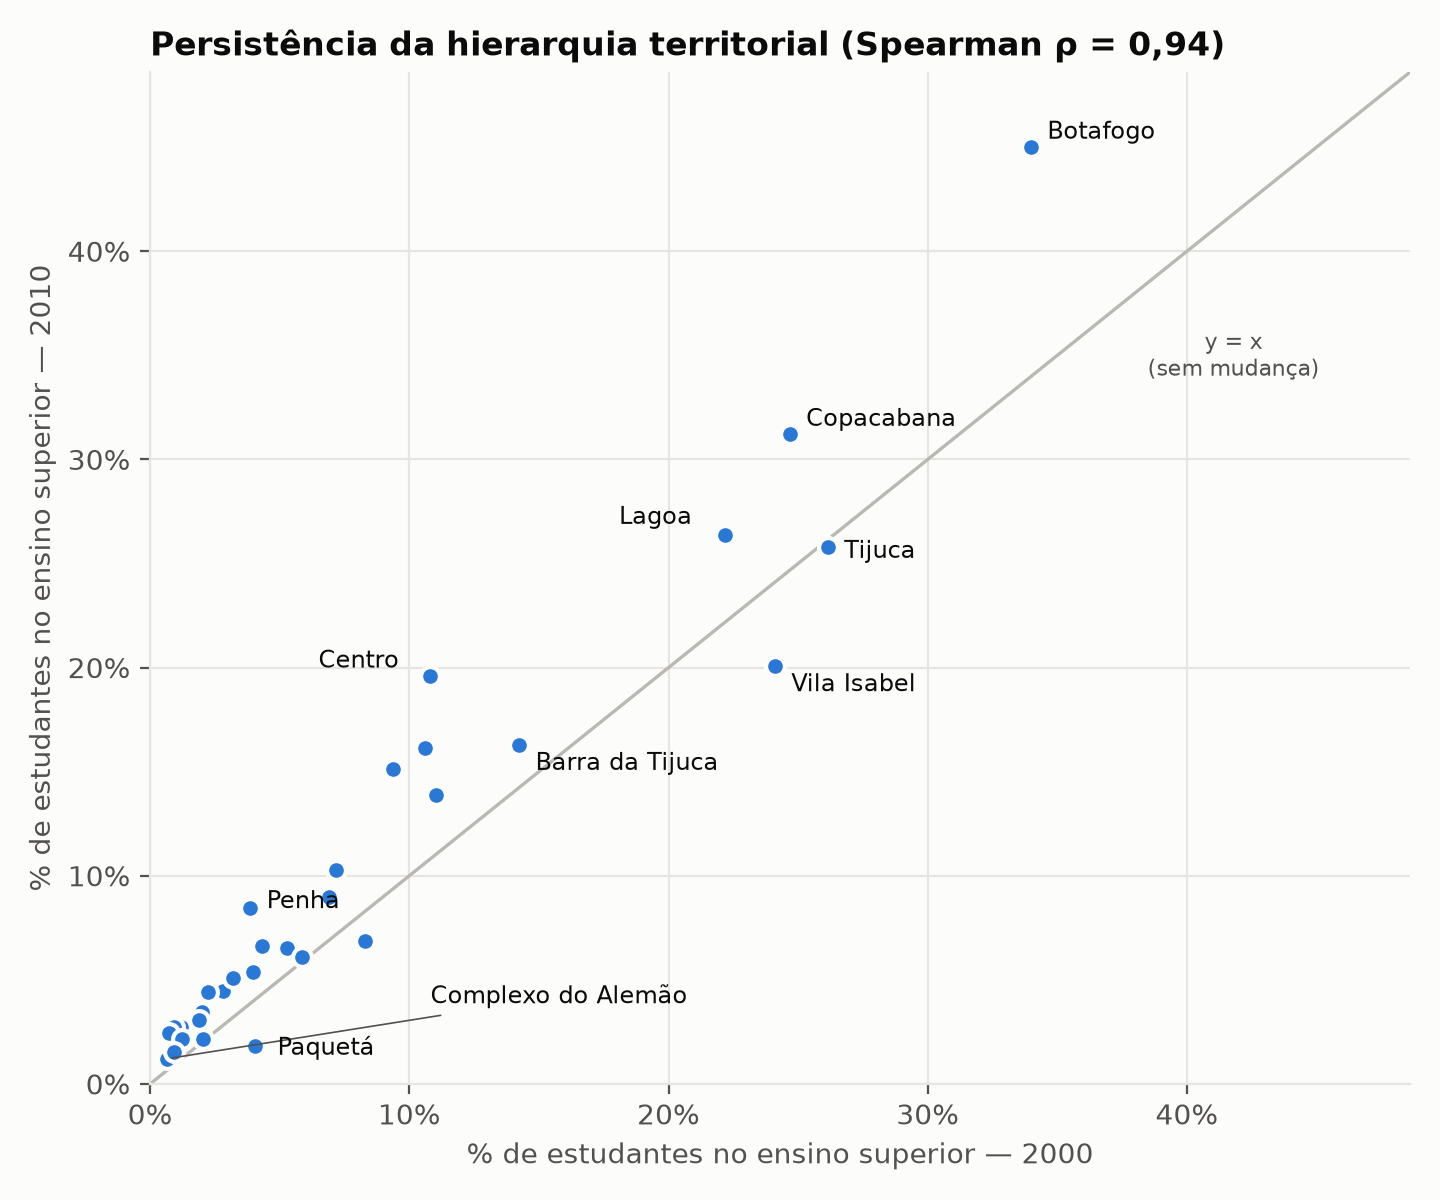

In [30]:
Image(filename=str(viz.PASTA_FIGURAS / "fig6_dispersao_superior.png"), width=620)

## 7. Síntese para o artigo
- **RQ1:** a rede pública ganhou estudantes (+12%), mas o fundamental regular encolheu (−9,4%) enquanto creche (+119%), EJA/supletivo (+230%) e ensino superior (+43%) cresceram.
- **RQ2:** a distribuição territorial se desconcentrou levemente (Gini 0,436 → 0,399); o crescimento foi puxado por AP4 (Barra/Jacarepaguá), AP1 (Portuária/São Cristóvão) e por áreas de favela da AP2/AP3 (Rocinha, Maré).
- **RQ3:** o peso do superior é extremamente desigual (de 1,2% no Complexo do Alemão a 45,0% em Botafogo, em 2010) e a hierarquia é persistente (ρ ≈ 0,94); a desigualdade relativa caiu levemente (CV 1,10 → 1,02), mas a distância absoluta aumentou (amplitude 33,3 → 43,8 p.p.). RA com maior peso do superior cresceram menos em número total de estudantes (Spearman ρ = −0,42; p = 0,018).